In [43]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

df = sn.load_dataset("titanic")
print(df.shape)

(891, 15)


In [2]:
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [3]:
print(df.dtypes)

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object


In [4]:
print(df.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [6]:
print(df.isna().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [9]:
print(df.duplicated().sum())

107


In [11]:
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print(len(dups))
dups.head(6)

160


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


In [12]:
print(df[["pclass", "class"]].drop_duplicates())

   pclass   class
0       3   Third
1       1   First
9       2  Second


In [13]:
print(df[["survived", "alive"]].drop_duplicates())

   survived alive
0         0    no
1         1   yes


In [14]:
print(df[["embarked", "embark_town"]].drop_duplicates())

   embarked  embark_town
0         S  Southampton
1         C    Cherbourg
5         Q   Queenstown
61      NaN          NaN


In [15]:
print((df.isna().mean() * 100).round(1))

survived        0.0
pclass          0.0
sex             0.0
age            19.9
sibsp           0.0
parch           0.0
fare            0.0
embarked        0.2
class           0.0
who             0.0
adult_male      0.0
deck           77.2
embark_town     0.2
alive           0.0
alone           0.0
dtype: float64


In [16]:
print((df["embarked"].isna() == df["embark_town"].isna()).all())

True


In [17]:
print(df.groupby("pclass")["age"].apply(lambda s: s.isna().mean()).round(3))

pclass
1    0.139
2    0.060
3    0.277
Name: age, dtype: float64


In [18]:
print(df["age"].median(), df["age"].mean())

28.0 29.69911764705882


In [22]:
print(df.groupby(["pclass", "sex"])["age"].median())

pclass  sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: age, dtype: float64


In [23]:
clean = df.copy()

group_median = clean.groupby(["pclass", "sex"])["age"].transform("median")
print(group_median.shape)
print(group_median.head())

(891,)
0    25.0
1    35.0
2    21.5
3    35.0
4    25.0
Name: age, dtype: float64


In [24]:
clean["age"] = clean["age"].fillna(group_median)
print(clean["age"].isna().sum())

0


In [25]:
clean["embarked"] = clean["embarked"].fillna(clean["embarked"].mode()[0])
clean["embark_town"] = clean["embark_town"].fillna(clean["embark_town"].mode()[0])

clean = clean.drop(columns=["deck"])
print(clean.shape)
print(clean.isna().sum().sum())

(891, 14)
0


In [30]:
print(clean[["age", "fare", "sibsp", "parch"]].describe().round(2))

          age    fare   sibsp   parch
count  891.00  891.00  891.00  891.00
mean    29.11   32.20    0.52    0.38
std     13.30   49.69    1.10    0.81
min      0.42    0.00    0.00    0.00
25%     21.50    7.91    0.00    0.00
50%     26.00   14.45    0.00    0.00
75%     36.00   31.00    1.00    0.00
max     80.00  512.33    8.00    6.00


In [32]:
print((clean["fare"] == 0).sum())
print(clean[clean["fare"] == 0][["pclass", "sex", "age", "fare"]].head())

15
     pclass   sex   age  fare
179       3  male  36.0   0.0
263       1  male  40.0   0.0
271       3  male  25.0   0.0
277       2  male  30.0   0.0
302       3  male  19.0   0.0


In [35]:
print((clean["age"] > 1).sum())
print(clean.nlargest(4, "fare")[["pclass", "sex", "age", "fare"]])

877
     pclass     sex   age      fare
258       1  female  35.0  512.3292
679       1    male  36.0  512.3292
737       1    male  35.0  512.3292
27        1    male  19.0  263.0000


In [36]:
for col in ["sex", "who", "class", "embarked"]:
    print(clean[col].value_counts(), "\n")

sex
male      577
female    314
Name: count, dtype: int64 

who
man      537
woman    271
child     83
Name: count, dtype: int64 

class
Third     491
First     216
Second    184
Name: count, dtype: int64 

embarked
S    646
C    168
Q     77
Name: count, dtype: int64 



In [39]:
q1 = clean["fare"].quantile(0.25)
q3 = clean["fare"].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print(q1, q3, iqr, low, high)

7.9104 31.0 23.0896 -26.724 65.6344


In [40]:
outliers = clean[(clean["fare"] < low) | (clean["fare"] > high)]
print(len(outliers))
print(outliers["pclass"].value_counts())
print(clean["fare"].mean(), clean["fare"].median())
print(clean["fare"].skew())

116
pclass
1    104
3      7
2      5
Name: count, dtype: int64
32.204207968574636 14.4542
4.787316519674893


In [41]:
print(outliers["pclass"].value_counts())
print(outliers["survived"].mean(), clean["survived"].mean())

pclass
1    104
3      7
2      5
Name: count, dtype: int64
0.6810344827586207 0.3838383838383838


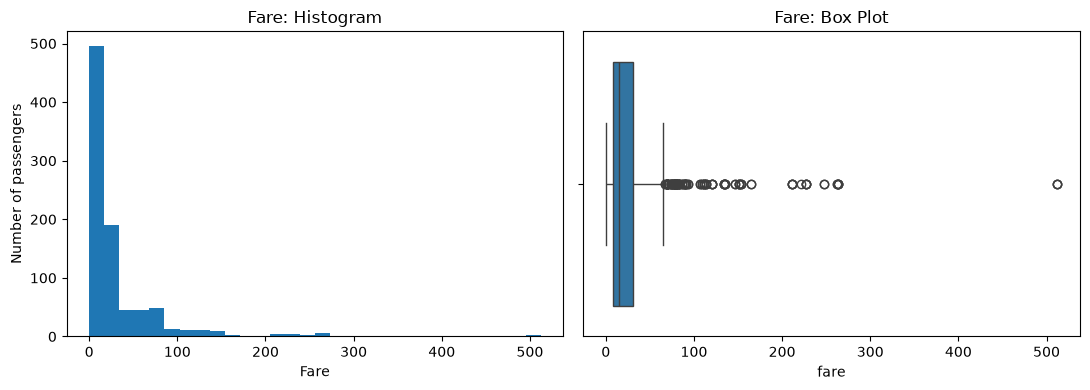

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(clean["fare"], bins=30)
axes[0].set_title("Fare: Histogram")
axes[0].set_xlabel("Fare")
axes[0].set_ylabel("Number of passengers")

sn.boxplot(x=clean["fare"], ax=axes[1])
axes[1].set_title("Fare: Box Plot")

plt.tight_layout()
plt.show()

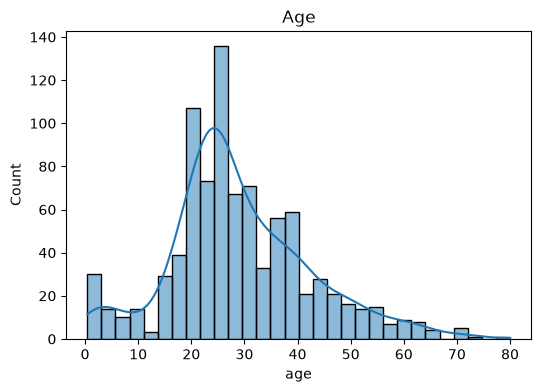

In [45]:
fig , ax = plt.subplots(figsize=(6,4))
sn.histplot(clean["age"], bins=30, kde=True, ax=ax)
ax.set_title("Age")
plt.show()

age
25.0    117
21.5     42
30.0     34
40.0     34
24.0     30
Name: count, dtype: int64
age
24.0    30
22.0    27
18.0    26
Name: count, dtype: int64


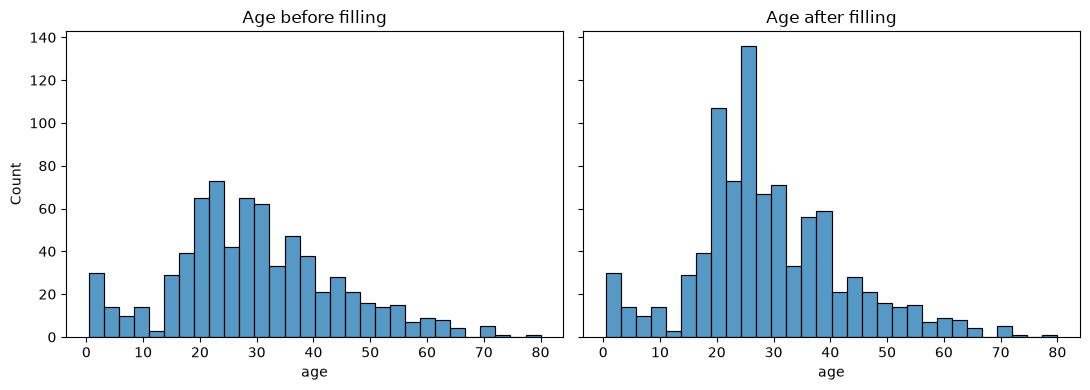

In [51]:
print(clean["age"].value_counts().head(5))     # 25.0 appears 117 times
print(df["age"].value_counts().head(3))        # before filling the top age appears only 30 times

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sn.histplot(df["age"].dropna(), bins=30, ax=axes[0])
axes[0].set_title("Age before filling")
sn.histplot(clean["age"], bins=30, ax=axes[1])
axes[1].set_title("Age after filling")
plt.tight_layout()
plt.show()

In [53]:
print(clean["pclass"].value_counts().sort_index())
print(clean["sex"].value_counts())

print(clean.groupby("pclass")["survived"].mean())
print(clean.groupby("sex")["survived"].mean())

pclass
1    216
2    184
3    491
Name: count, dtype: int64
sex
male      577
female    314
Name: count, dtype: int64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


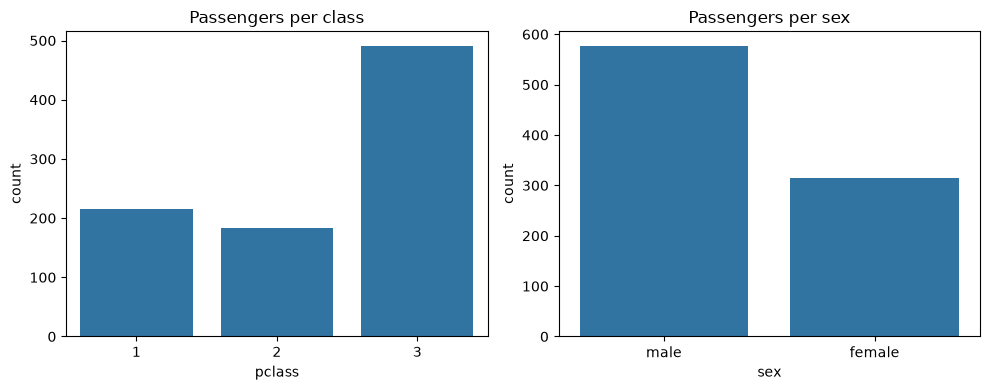

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sn.countplot(data=clean, x="pclass", ax=axes[0])
axes[0].set_title("Passengers per class")

sn.countplot(data=clean, x="sex", ax=axes[1])
axes[1].set_title("Passengers per sex")

plt.tight_layout()
plt.show()

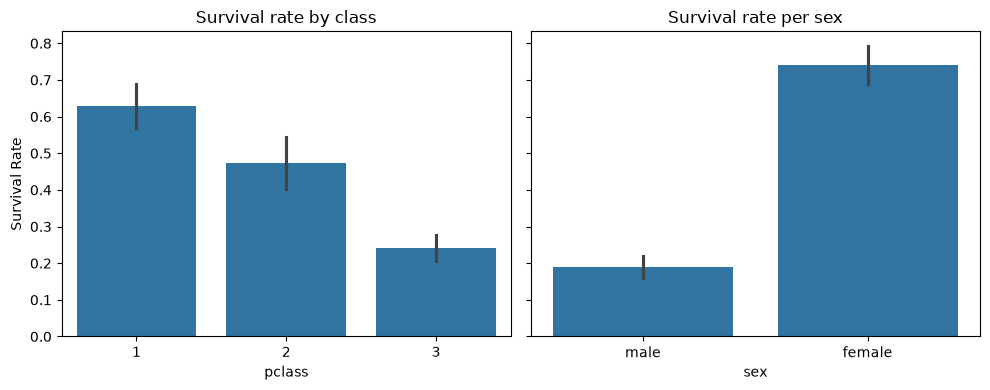

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

sn.barplot(data=clean, x="pclass", y="survived", ax=axes[0])
axes[0].set_title("Survival rate by class")
axes[0].set_ylabel("Survival Rate")

sn.barplot(data=clean, x="sex", y="survived", ax=axes[1])
axes[1].set_title("Survival rate per sex")

plt.tight_layout()
plt.show()

In [57]:
print(clean.groupby("pclass")["survived"].sum())

pclass
1    136
2     87
3    119
Name: survived, dtype: int64


In [63]:
print(clean.groupby(["pclass", "sex"])["survived"].mean())

pclass  sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: survived, dtype: float64


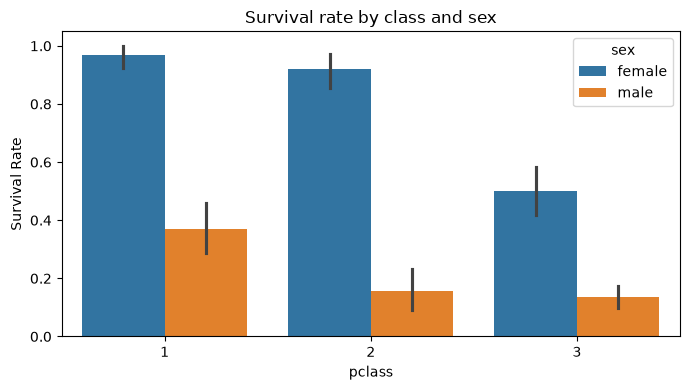

In [61]:
plt.figure(figsize=(7,4))
sn.barplot(data=clean, x="pclass", y="survived", hue="sex")
plt.title("Survival rate by class and sex")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

In [72]:
cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
corr = clean[cols].corr()
print(corr.round(2))

          survived  pclass   age  sibsp  parch  fare
survived      1.00   -0.34 -0.06  -0.04   0.08  0.26
pclass       -0.34    1.00 -0.41   0.08   0.02 -0.55
age          -0.06   -0.41  1.00  -0.25  -0.18  0.12
sibsp        -0.04    0.08 -0.25   1.00   0.41  0.16
parch         0.08    0.02 -0.18   0.41   1.00  0.22
fare          0.26   -0.55  0.12   0.16   0.22  1.00


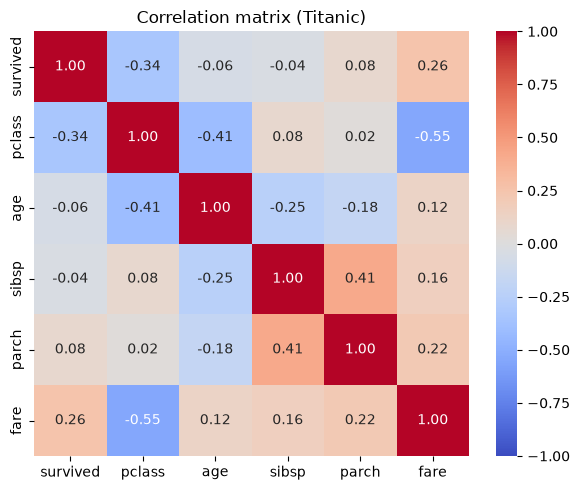

In [74]:
plt.figure(figsize=(6,5))
sn.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1)
plt.title("Correlation matrix (Titanic)")
plt.tight_layout()
plt.show()

In [79]:
clean["is_female"] = (clean["sex"] == "female").astype(int)
print(clean["is_female"].value_counts())

is_female
0    577
1    314
Name: count, dtype: int64


In [80]:
cols = ["survived", "is_female", "pclass", "age", "sibsp", "parch", "fare"]
corr = clean[cols].corr()
print(corr.round(2)["survived"])

survived     1.00
is_female    0.54
pclass      -0.34
age         -0.06
sibsp       -0.04
parch        0.08
fare         0.26
Name: survived, dtype: float64
